# Tratamento de dados — Iniciação à Pesquisa I - nanopartículas de sílica (Stöber)
-----------------------------------------------------------------
Alunas: Gabriela O. de Lima Cabral e Giovanna Avellar Machado <br>
Notebook para tratar os dados e gerar os gráficos do relatório.

**Como usar:**
1. Coloque o arquivo de dados na mesma pasta deste notebook. 
2. Ajuste o nome do arquivo e a aparência na célula de **Configurações**.
3. Rode as células em ordem (*Runtime → Run all* no Colab, ou *Run All* no Jupyter).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import savgol_filter
from scipy import sparse
from scipy.sparse.linalg import spsolve

## Configurações

In [2]:
# ===== Arquivo de dados =====
ARQ_RAMAN_NP = "dados_FTIR_RAMAN_MEV/ramannp.txt"

# ===== Aparência =====
FUNDO_ESCURO = False    # True = visual escuro e PNG transparente com linhas claras (slides escuros)
                        # False = fundo branco e linhas escuras (relatório, slide claro)
SALVAR = True           # salva os gráficos em PNG (300 dpi)

# ===== Faixas =====
X_MIN, X_MAX = 300, 3450         # faixa tratada (abaixo de ~300 cm⁻¹: corte do filtro do laser)
X_REDE = (300, 1250)             # faixa da rede Si–O–Si, mostrada no gráfico principal

In [3]:
plt.rcdefaults()
if FUNDO_ESCURO:
    FUNDO = "#231D1F"
    TXT, GRID = "#F4ECE8", "#8C8285"
    COR = "#de295f"         # rosa (mesma cor das NPs nos slides)
    SUF = "_escuro"
else:
    FUNDO = "white"
    TXT, GRID = "#222222", "#AAAAAA"
    COR = "#C0392B"         # vermelho
    SUF = "_claro"

plt.rcParams.update({
    "font.size": 13, "text.color": TXT, "axes.labelcolor": TXT,
    "xtick.color": TXT, "ytick.color": TXT, "axes.edgecolor": TXT,
    "figure.facecolor": FUNDO, "axes.facecolor": FUNDO,
    "legend.labelcolor": TXT,
})

def salvar(fig, nome):
    if SALVAR:
        arquivo = nome.replace(".png", SUF + ".png")
        fig.savefig(arquivo, dpi=300, transparent=FUNDO_ESCURO, bbox_inches="tight")
        print("Salvo:", arquivo)

## Funções de tratamento

- **`ler_espectro`**: lê o arquivo e ordena o eixo x em ordem crescente.
- **`linha_base_als`**: linha de base por *asymmetric least squares* (Eilers & Boelens, 2005). Acompanha o fundo curvo (fluorescência e asa do espalhamento Rayleigh) sem "comer" as bandas. `lam` controla a rigidez da curva (maior = mais rígida).
- **`achar_pico`**: encontra a posição e a altura do máximo de uma banda no espectro suavizado, dentro de uma janela.

In [4]:
def ler_espectro(arquivo):
    dados = np.loadtxt(arquivo, comments="#")
    x, y = dados[:, 0], dados[:, 1].astype(float)
    ordem = np.argsort(x)
    return x[ordem], y[ordem]

def recortar(x, y, xmin, xmax):
    m = (x >= xmin) & (x <= xmax)
    return x[m], y[m]

def linha_base_als(y, lam=1e6, p=0.01, n_iter=25):
    L = len(y)
    D = sparse.diags([1.0, -2.0, 1.0], [0, -1, -2], shape=(L, L - 2))
    D = lam * D.dot(D.T)
    w = np.ones(L)
    for _ in range(n_iter):
        z = spsolve(sparse.csc_matrix(sparse.diags(w) + D), w * y)
        w = p * (y > z) + (1 - p) * (y < z)
    return z

def achar_pico(x, y_suave, faixa):
    m = (x > faixa[0]) & (x < faixa[1])
    i = np.argmax(y_suave[m])
    return x[m][i], y_suave[m][i]

## 1. Espectro bruto (como saiu do equipamento)

O fundo cai de forma contínua desde os números de onda baixos: é a asa do espalhamento Rayleigh somada à fluorescência. As bandas da sílica ficam por cima desse fundo; a mais visível é a de 440–490 cm⁻¹.

Salvo: raman_silica_bruto_claro.png


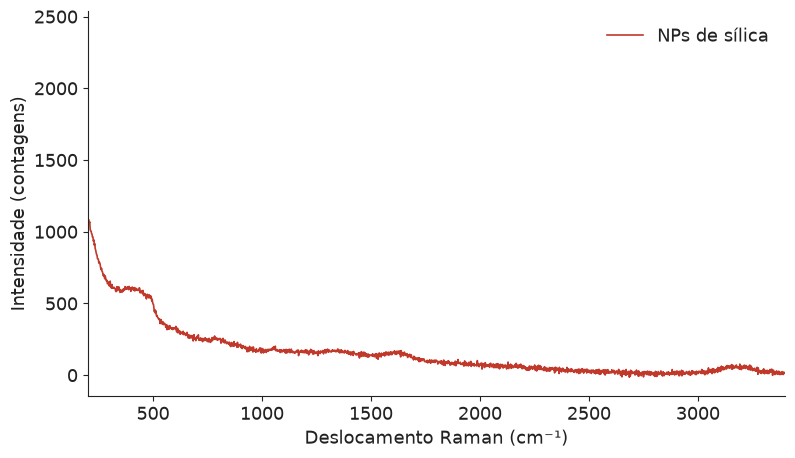

In [5]:
x_bruto, y_bruto = ler_espectro(ARQ_RAMAN_NP)

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(x_bruto, y_bruto, color=COR, lw=1.2, label="NPs de sílica")
ax.set_xlim(200, 3400)   # abaixo de ~200 cm⁻¹ há o corte do filtro do laser
ax.set_xlabel("Deslocamento Raman (cm⁻¹)")
ax.set_ylabel("Intensidade (contagens)")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
salvar(fig, "raman_silica_bruto.png")
plt.show()

## 2. Tratamento: recorte, linha de base e suavização

No gráfico de conferência, o espectro bruto fica claro ao fundo e a curva suavizada por cima, no mesmo estilo dos gráficos finais. A suavização (Savitzky–Golay, janela de 31 pontos) não altera a posição das bandas; ela só reduz o ruído para facilitar a leitura.

Salvo: raman_silica_linha_base_claro.png


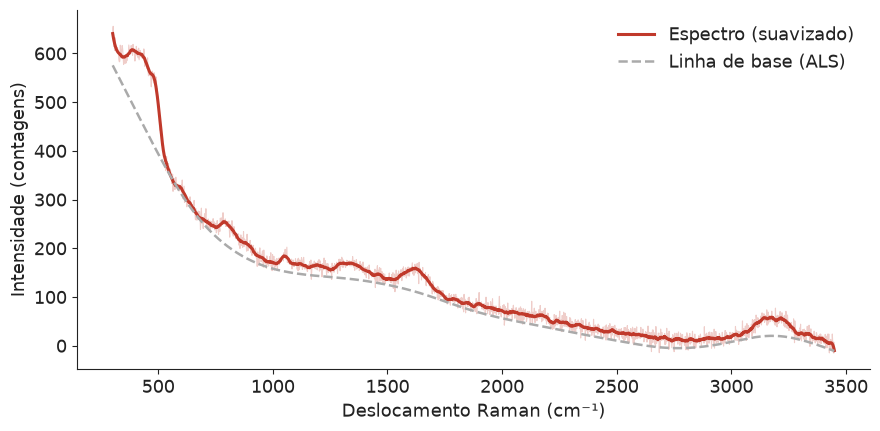

In [6]:
x, y = recortar(x_bruto, y_bruto, X_MIN, X_MAX)
base = linha_base_als(y, lam=1e6, p=0.01)
corr = y - base
suave = savgol_filter(corr, window_length=31, polyorder=3)

# Conferência visual da linha de base
fig, ax = plt.subplots(figsize=(9, 4.5))
y_suave = savgol_filter(y, window_length=31, polyorder=3)   # só para visualização
ax.plot(x, y, color=COR, alpha=0.25, lw=0.8)                 # espectro bruto, ao fundo
ax.plot(x, y_suave, color=COR, lw=2.2, label="Espectro (suavizado)")
ax.plot(x, base, color=GRID, ls="--", lw=1.8, label="Linha de base (ALS)")
ax.set_xlabel("Deslocamento Raman (cm⁻¹)")
ax.set_ylabel("Intensidade (contagens)")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
plt.tight_layout()
salvar(fig, "raman_silica_linha_base.png")
plt.show()

## 3. Posições das bandas

In [7]:
BANDAS = {                       # nome: (janela de busca em cm⁻¹, rótulo no gráfico)
    "R":    ((380, 520),   "Si–O–Si"),
    "D2":   ((560, 650),   "D2"),
    "SS":   ((740, 880),   "Si–O–Si"),
    "AS":   ((1000, 1100), "Si–O–Si"),
    "OH":   ((3050, 3350), "O–H"),
}
picos = {k: achar_pico(x, suave, faixa) for k, (faixa, _) in BANDAS.items()}

descricao = {"R": "deformação Si–O–Si (rede; D1 em ~490)",
             "D2": "anéis de 3 membros (D2)",
             "SS": "estiramento simétrico Si–O–Si",
             "AS": "estiramento assimétrico Si–O–Si",
             "OH": "estiramento O–H (Si–OH e H₂O)"}
print(f"{'Posição (cm⁻¹)':>15s}   Atribuição")
for k, (pos, alt) in picos.items():
    print(f"{pos:15.0f}   {descricao[k]}")

 Posição (cm⁻¹)   Atribuição
            439   deformação Si–O–Si (rede; D1 em ~490)
            601   anéis de 3 membros (D2)
            798   estiramento simétrico Si–O–Si
           1048   estiramento assimétrico Si–O–Si
           3176   estiramento O–H (Si–OH e H₂O)


## 4. Gráfico principal: rede Si–O–Si

Espectro corrigido ao fundo (claro), curva suavizada por cima e as bandas marcadas com linha tracejada e posição.

Salvo: raman_silica_rede_claro.png


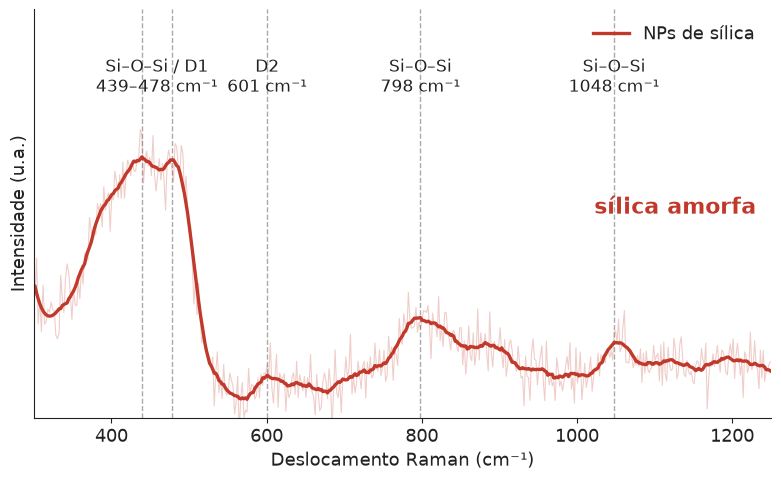

In [8]:
xr, cr = recortar(x, corr, *X_REDE)
_, sr = recortar(x, suave, *X_REDE)
topo = picos["R"][1]

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(xr, cr, color=COR, alpha=0.25, lw=0.8)
ax.plot(xr, sr, color=COR, lw=2.4, label="NPs de sílica")
# banda larga da rede: dois máximos (deformação Si–O–Si e D1)
p1 = picos["R"][0]
p2, _ = achar_pico(xr, sr, (p1 + 25, 520))
for pos in (p1, p2):
    ax.axvline(pos, color=GRID, ls="--", lw=1, zorder=0)
ax.text((p1 + p2) / 2, topo * 1.25, f"Si–O–Si / D1\n{p1:.0f}–{p2:.0f} cm⁻¹",
        ha="center", va="bottom", fontsize=12)
for k in ["D2", "SS", "AS"]:
    pos = picos[k][0]
    ax.axvline(pos, color=GRID, ls="--", lw=1, zorder=0)
    ax.text(pos, topo * 1.25, f"{BANDAS[k][1]}\n{pos:.0f} cm⁻¹",
            ha="center", va="bottom", fontsize=12)
ax.text(0.98, 0.5, "sílica amorfa", transform=ax.transAxes,
        ha="right", fontsize=16, color=COR, fontweight="bold")
ax.set_xlim(*X_REDE)
ax.set_ylim(min(sr.min(), 0) - 0.08 * topo, topo * 1.62)
ax.set_xlabel("Deslocamento Raman (cm⁻¹)")
ax.set_ylabel("Intensidade (u.a.)")
ax.set_yticks([])
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="upper right")
plt.tight_layout()
salvar(fig, "raman_silica_rede.png")
plt.show()

## 5. Espectro completo tratado

Mostra também a banda de O–H em ~3200 cm⁻¹, que indica grupos silanol (Si–OH) e água adsorvida na superfície. As bandas marcadas com **\*** (≈1340 e ≈1620 cm⁻¹) não pertencem à sílica: provavelmente vêm de carbono residual dos grupos etoxi do TEOS, degradados pelo laser (a de 1620 pode ter contribuição da água).

Salvo: raman_silica_completo_claro.png


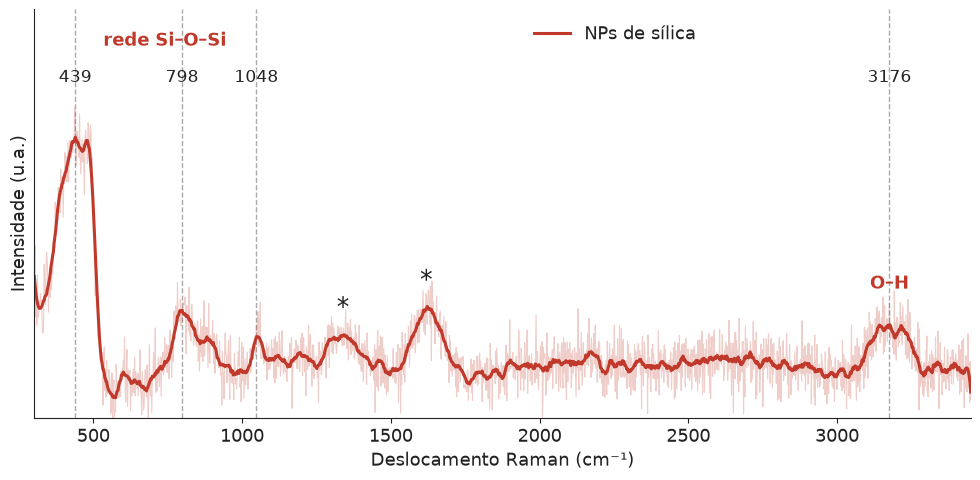

In [9]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(x, corr, color=COR, alpha=0.25, lw=0.8)
ax.plot(x, suave, color=COR, lw=2.2, label="NPs de sílica")
for k in ["R", "SS", "AS", "OH"]:
    pos = picos[k][0]
    ax.axvline(pos, color=GRID, ls="--", lw=1, zorder=0)
    ax.text(pos, topo * 1.2, f"{pos:.0f}", ha="center", va="bottom", fontsize=12)
for pos in (1340, 1620):
    i = np.argmin(abs(x - pos))
    ax.text(pos, suave[i] + 0.06 * topo, "*", ha="center", va="bottom", fontsize=18, color=TXT)
ax.text(picos["OH"][0], picos["OH"][1] + 0.14 * topo, "O–H", ha="center", fontsize=13,
        color=COR, fontweight="bold")
ax.text(740, topo * 1.34, "rede Si–O–Si", ha="center", va="bottom", fontsize=13,
        color=COR, fontweight="bold")
ax.set_xlim(X_MIN, X_MAX)
ax.set_ylim(min(suave.min(), 0) - 0.08 * topo, topo * 1.5)
ax.set_xlabel("Deslocamento Raman (cm⁻¹)")
ax.set_ylabel("Intensidade (u.a.)")
ax.set_yticks([])
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.62, 1.0))
plt.tight_layout()
salvar(fig, "raman_silica_completo.png")
plt.show()

---
# FTIR das nanopartículas de sílica

O arquivo exportado pelo equipamento tem linhas de cabeçalho começando com `##`, que o código ignora. O eixo x fica invertido (de 4000 para 400 cm⁻¹), que é a convenção do FTIR.

In [10]:
ARQ_FTIR_NP = "dados_FTIR_RAMAN_MEV/ftir_np_si.txt"

BANDAS_FTIR = [(3400, "O–H"), (1632, "H–O–H"), (1180, "Si–O–Si (LO)"),
               (1079, "Si–O–Si"), (961, "Si–OH"), (797, "Si–O–Si"), (451, "Si–O–Si (def.)")]

def ler_ftir(arquivo, xmin=400, xmax=4000):
    dados = np.loadtxt(arquivo, comments="##")
    ordem = np.argsort(dados[:, 0])
    x, y = dados[ordem, 0], dados[ordem, 1]
    m = (x >= xmin) & (x <= xmax)
    return x[m], y[m]

x_f, t_f = ler_ftir(ARQ_FTIR_NP)
t_s = savgol_filter(t_f, 15, 3)

# posição exata de cada banda (mínimo de transmitância perto do valor nominal)
def minimo(x, t, pos, janela=40):
    m = (x > pos - janela) & (x < pos + janela)
    return x[m][np.argmin(t[m])]

print(f"{'Banda':>16s}{'Posição (cm⁻¹)':>16s}")
for pos, rot in BANDAS_FTIR:
    if rot == "Si–O–Si (LO)":
        print(f"{rot:>16s}{minimo(x_f, t_s, 1150, 20):10.0f} e {minimo(x_f, t_s, 1205, 20):.0f}")
        continue
    jan = 300 if rot == "O–H" else 40
    print(f"{rot:>16s}{minimo(x_f, t_s, pos, jan):16.0f}")

           Banda  Posição (cm⁻¹)
             O–H            3209
           H–O–H            1632
    Si–O–Si (LO)      1151 e 1206
         Si–O–Si            1079
           Si–OH             961
         Si–O–Si             797
  Si–O–Si (def.)             451


## 6. Espectro completo

Salvo: ftir_silica_claro.png


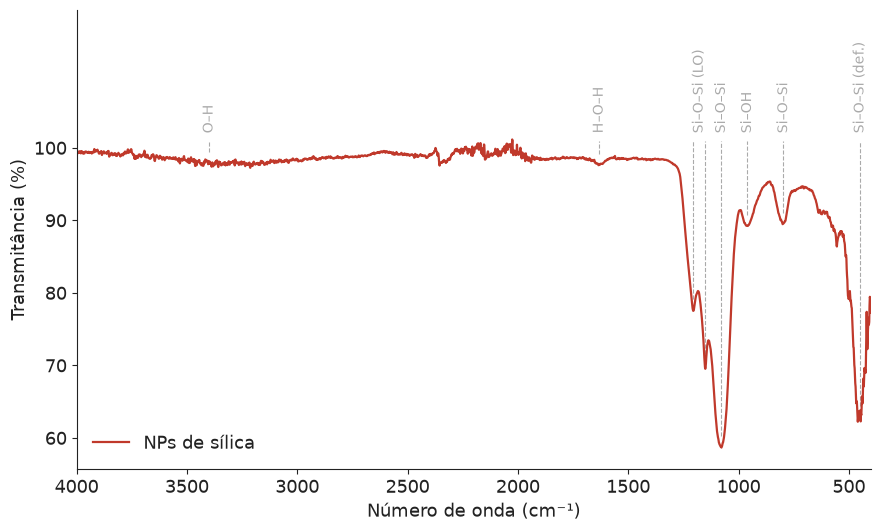

In [11]:
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.plot(x_f, t_f, color=COR, lw=1.6, label="NPs de sílica")
topo = 100
for pos, rot in BANDAS_FTIR:
    i = np.argmin(abs(x_f - pos))
    if rot == "Si–O–Si (LO)":      # ombro duplo: marca os dois mínimos (~1150 e ~1205)
        for p_ in (minimo(x_f, t_s, 1150, 20), minimo(x_f, t_s, 1205, 20)):
            j = np.argmin(abs(x_f - p_))
            ax.plot([p_, p_], [t_s[j] + 1.5, topo + 1], color=GRID, ls="--", lw=0.8, zorder=0)
    else:
        ax.plot([pos, pos], [t_s[i] + 1.5, topo + 1], color=GRID, ls="--", lw=0.8, zorder=0)
    ax.text(pos, topo + 2, rot, rotation=90, ha="center", va="bottom", fontsize=10, color=GRID)
ax.set_xlim(4000, 400)          # eixo invertido, convenção do FTIR
ax.set_ylim(t_f.min() - 3, topo + 19)
ax.set_yticks(np.arange(60, 101, 10))
ax.set_xlabel("Número de onda (cm⁻¹)")
ax.set_ylabel("Transmitância (%)")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="lower left")
plt.tight_layout()
salvar(fig, "ftir_silica.png")
plt.show()

## 7. Detalhe da região de O–H e água

As bandas de O–H (3000–3700 cm⁻¹) e de água (1632 cm⁻¹) são fracas na escala completa. Ampliando o eixo y, elas ficam visíveis.

Salvo: ftir_silica_OH_claro.png


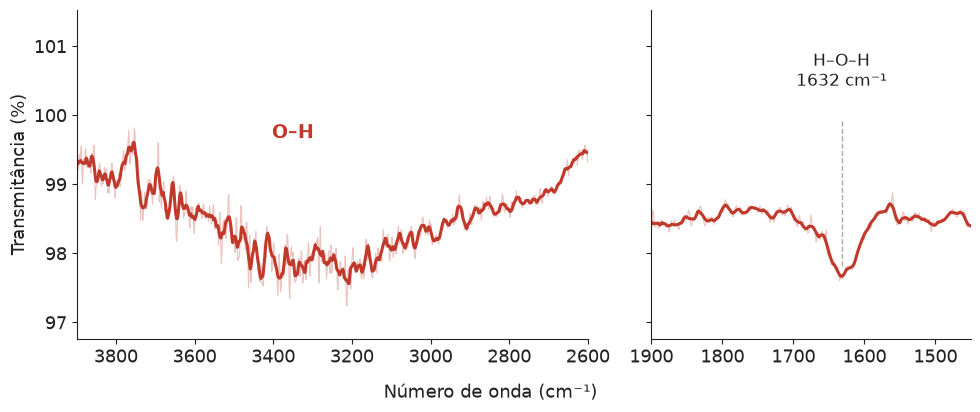

In [12]:
fig, axs = plt.subplots(1, 2, figsize=(10, 4.2), sharey=True,
                        gridspec_kw={"width_ratios": [1.6, 1]})
for ax, (a, b) in zip(axs, [(3900, 2600), (1900, 1450)]):
    m = (x_f <= a) & (x_f >= b)
    ax.plot(x_f[m], t_f[m], color=COR, alpha=0.3, lw=0.8)
    ax.plot(x_f[m], t_s[m], color=COR, lw=2.2)
    ax.set_xlim(a, b)
    ax.spines[["top", "right"]].set_visible(False)
m = (x_f <= 3900) & (x_f >= 1450)
axs[0].set_ylim(t_s[m].min() - 0.8, t_s[m].max() + 1.2)
axs[0].text(3350, 99.6, "O–H", ha="center", va="bottom", fontsize=14,
            color=COR, fontweight="bold")
p_agua = minimo(x_f, t_s, 1632)
j = np.argmin(abs(x_f - p_agua))
axs[1].plot([p_agua, p_agua], [t_s[j] + 0.15, t_s[m].max() - 0.4], color=GRID, ls="--", lw=1, zorder=0)
axs[1].text(p_agua, t_s[m].max() + 0.6, f"H–O–H\n{p_agua:.0f} cm⁻¹", ha="center",
            va="top", fontsize=12)
axs[0].set_ylabel("Transmitância (%)")
plt.tight_layout()
fig.supxlabel("Número de onda (cm⁻¹)", fontsize=13, y=0.02)
fig.subplots_adjust(bottom=0.17)
salvar(fig, "ftir_silica_OH.png")
plt.show()

## Estudo de condutividade

In [13]:
"""Gráfico de ΔT (T_quente − T_fria) das placas de epóxi e epóxi + LAS.

Pares de pontos: 1–4, 2–5 e 3–6 (extremidade quente − extremidade fria).
Gera duas versões: _claro (relatório) e _escuro (fundo transparente, para slides).
Uso: python3 grafico_deltaT.py
"""
import numpy as np, matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

dados = {
    "Epóxi":       {"quente": [34.5, 30.4, 31.3], "fria": [28.3, 28.3, 28.1]},
    "Epóxi + LAS": {"quente": [33.5, 30.5, 34.9], "fria": [29.1, 28.5, 27.9]},
}
for nome, d in dados.items():
    d["dT"] = np.array(d["quente"]) - np.array(d["fria"])
    print(nome, d["dT"], round(d["dT"].mean(), 2), round(d["dT"].std(ddof=1), 2))

def br(v, n=1):
    return f"{v:.{n}f}".replace(".", ",")

for FUNDO_ESCURO in (False, True):
    if FUNDO_ESCURO:
        FUNDO, TXT, GRID, COR, SUF = "#231D1F", "#F4ECE8", "#8C8285", "#de295f", "_escuro"
    else:
        FUNDO, TXT, GRID, COR, SUF = "white", "#222222", "#AAAAAA", "#C0392B", "_claro"
    plt.rcParams.update({
        "font.size": 13, "text.color": TXT, "axes.labelcolor": TXT,
        "xtick.color": TXT, "ytick.color": TXT, "axes.edgecolor": TXT,
        "figure.facecolor": FUNDO, "axes.facecolor": FUNDO, "legend.labelcolor": TXT,
    })
    cores = [GRID, COR]
    fig, ax = plt.subplots(figsize=(5.2, 4.6))
    for i, (nome, d) in enumerate(dados.items()):
        m, s = d["dT"].mean(), d["dT"].std(ddof=1)
        ax.bar(i, m, width=0.55, color=cores[i], alpha=0.35 if i == 0 else 0.30,
               edgecolor=cores[i], linewidth=2, zorder=1)
        ax.errorbar(i - 0.06, m, yerr=s, color=TXT, capsize=8, lw=1.6, capthick=1.6, zorder=3)
        jit = np.array([0.16, 0.16, 0.16])
        ax.scatter(i + jit, d["dT"], s=70, color=cores[i], edgecolor=FUNDO, linewidth=1.5, zorder=4)
        for k, (xx, yy) in enumerate(zip(i + jit, d["dT"])):
            ax.text(xx + 0.06, yy, f"{k+1}–{k+4}", fontsize=10, color=TXT, va="center", ha="left")
        ax.text(i, max(m + s, d["dT"].max()) + 0.35, f"{br(m)} ± {br(s)} °C", ha="center", va="bottom",
                fontsize=13, fontweight="bold", color=TXT)
    ax.set_xticks([0, 1], list(dados.keys()))
    ax.set_xlim(-0.6, 1.6)
    ax.set_ylim(0, 9)
    ax.set_ylabel(r"$\Delta T = T_{\mathrm{quente}} - T_{\mathrm{fria}}$ (°C)")
    ax.spines[["top", "right"]].set_visible(False)
    plt.tight_layout()
    fig.savefig(f"deltaT_placas{SUF}.png", dpi=300,
                transparent=FUNDO_ESCURO, bbox_inches="tight")
    plt.close(fig)

Epóxi [6.2 2.1 3.2] 3.83 2.12
Epóxi + LAS [4.4 2.  7. ] 4.47 2.5


Epóxi [6.2 2.1 3.2] 3.83 2.12
Epóxi + LAS [4.4 2.  7. ] 4.47 2.5
Salvo em: c:\Users\gabriela2610013\OneDrive - ILUM ESCOLA DE CIÊNCIA\Área de Trabalho\Relatório IP-1\deltaT_placas_claro.png


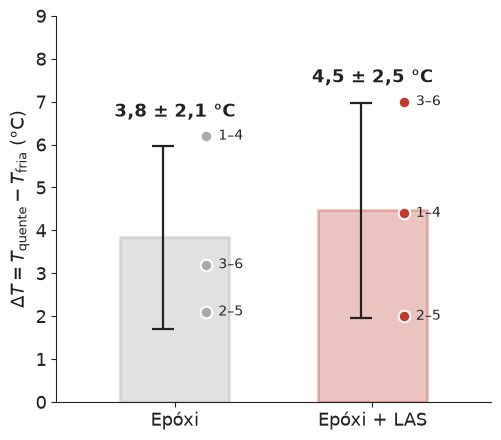

Salvo em: c:\Users\gabriela2610013\OneDrive - ILUM ESCOLA DE CIÊNCIA\Área de Trabalho\Relatório IP-1\deltaT_placas_escuro.png


In [14]:
"""Gráfico de ΔT (T_quente − T_fria) das placas de epóxi e epóxi + LAS.

Pares de pontos: 1–4, 2–5 e 3–6 (extremidade quente − extremidade fria).
Gera duas versões: _claro (relatório) e _escuro (fundo transparente, para slides).
Uso: python3 grafico_deltaT.py
"""
%matplotlib inline
import os
import numpy as np
import matplotlib.pyplot as plt

dados = {
    "Epóxi":       {"quente": [34.5, 30.4, 31.3], "fria": [28.3, 28.3, 28.1]},
    "Epóxi + LAS": {"quente": [33.5, 30.5, 34.9], "fria": [29.1, 28.5, 27.9]},
}
for nome, d in dados.items():
    d["dT"] = np.array(d["quente"]) - np.array(d["fria"])
    print(nome, d["dT"], round(d["dT"].mean(), 2), round(d["dT"].std(ddof=1), 2))

def br(v, n=1):
    return f"{v:.{n}f}".replace(".", ",")

for FUNDO_ESCURO in (False, True):
    if FUNDO_ESCURO:
        FUNDO, TXT, GRID, COR, SUF = "#231D1F", "#F4ECE8", "#8C8285", "#de295f", "_escuro"
    else:
        FUNDO, TXT, GRID, COR, SUF = "white", "#222222", "#AAAAAA", "#C0392B", "_claro"
    plt.rcParams.update({
        "font.size": 13, "text.color": TXT, "axes.labelcolor": TXT,
        "xtick.color": TXT, "ytick.color": TXT, "axes.edgecolor": TXT,
        "figure.facecolor": FUNDO, "axes.facecolor": FUNDO, "legend.labelcolor": TXT,
    })
    cores = [GRID, COR]
    fig, ax = plt.subplots(figsize=(5.2, 4.6))
    for i, (nome, d) in enumerate(dados.items()):
        m, s = d["dT"].mean(), d["dT"].std(ddof=1)
        ax.bar(i, m, width=0.55, color=cores[i], alpha=0.35 if i == 0 else 0.30,
               edgecolor=cores[i], linewidth=2, zorder=1)
        ax.errorbar(i - 0.06, m, yerr=s, color=TXT, capsize=8, lw=1.6, capthick=1.6, zorder=3)
        jit = np.array([0.16, 0.16, 0.16])
        ax.scatter(i + jit, d["dT"], s=70, color=cores[i], edgecolor=FUNDO, linewidth=1.5, zorder=4)
        for k, (xx, yy) in enumerate(zip(i + jit, d["dT"])):
            ax.text(xx + 0.06, yy, f"{k+1}–{k+4}", fontsize=10, color=TXT, va="center", ha="left")
        ax.text(i, max(m + s, d["dT"].max()) + 0.35, f"{br(m)} ± {br(s)} °C", ha="center", va="bottom",
                fontsize=13, fontweight="bold", color=TXT)
    ax.set_xticks([0, 1], list(dados.keys()))
    ax.set_xlim(-0.6, 1.6)
    ax.set_ylim(0, 9)
    ax.set_ylabel(r"$\Delta T = T_{\mathrm{quente}} - T_{\mathrm{fria}}$ (°C)")
    ax.spines[["top", "right"]].set_visible(False)
    plt.tight_layout()
    arquivo = f"deltaT_placas{SUF}.png"
    fig.savefig(arquivo, dpi=300, transparent=FUNDO_ESCURO, bbox_inches="tight")
    print("Salvo em:", os.path.abspath(arquivo))
    if not FUNDO_ESCURO:
        plt.show()          # mostra a versão clara na tela
    plt.close(fig)

## MEV

n = 800 (removidas 1 duplicadas)
média ± DP = 19.0 ± 6.2 nm | mediana = 18.2 nm | mín–máx = 7.5–48.0 nm
log-normal: mediana = 18.1 nm, desvio geométrico = 1.36
1ª série: n = 499, 19.3 ± 6.5 nm
2ª série: n = 161, 18.6 ± 5.8 nm
3ª série: n = 140, 18.6 ± 5.4 nm
Welch 1ª série × 2ª série: t = 1.20, p = 0.23
Welch 1ª série × 3ª série: t = 1.24, p = 0.22
Welch 2ª série × 3ª série: t = 0.04, p = 0.97
coeficiente de variação = 33% | PDI equivalente (CV²) = 0.11
área superficial específica estimada = 158 m²/g (ρ = 2.0 g/cm³)
Salvo em: c:\Users\gabriela2610013\OneDrive - ILUM ESCOLA DE CIÊNCIA\Área de Trabalho\Relatório IP-1\histograma_mev_claro.png


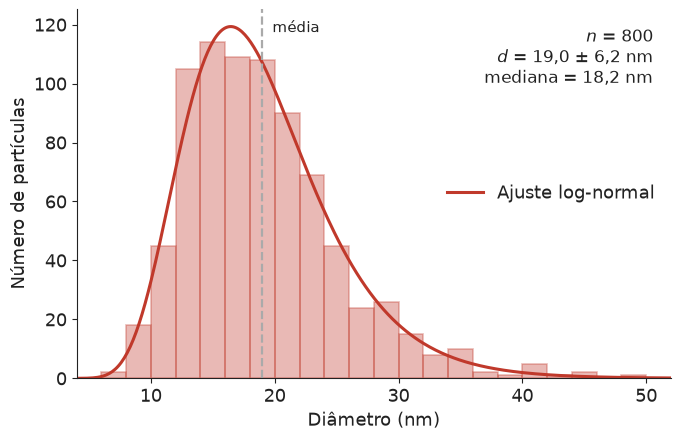

Salvo em: c:\Users\gabriela2610013\OneDrive - ILUM ESCOLA DE CIÊNCIA\Área de Trabalho\Relatório IP-1\histograma_mev_escuro.png


In [15]:
"""Histograma do diâmetro das nanopartículas de sílica medidas no MEV (Fiji/ImageJ).

Lê a tabela Results exportada do Fiji (coluna Length na última posição),
corrige a escala, remove medidas duplicadas e gera o histograma com ajuste log-normal.
Gera duas versões: _claro (relatório) e _escuro (fundo transparente, para slides).
Uso: python3 histograma_mev.py
"""
import os
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

ARQUIVO = "dados_FTIR_RAMAN_MEV/aglomerados.csv" # tabela Results do Fiji (separada por tab)
# A calibração usada no Fiji fez a barra de 500 nm medir 3375 "nm";
# por isso todas as medidas são multiplicadas por 500/3375.
FATOR = 500 / 3375
# Séries de medida (números das linhas da tabela do Fiji, inclusive)
SERIES = {"1ª série": (1, 500), "2ª série": (501, 661), "3ª série": (662, 801)}
DENSIDADE_SILICA = 2.0   # g/cm³, valor típico para sílica de Stöber (suposição)

# ---------- Leitura ----------
import csv
ULTIMA_LINHA = 801      # linhas depois desta (ex.: medidas de forma) são ignoradas

texto = open(ARQUIVO, encoding="utf-8-sig").read().splitlines()
sep = "\t" if "\t" in texto[0] else ","            # aceita .txt (tab) ou .csv (vírgula)
tabela = [l for l in csv.reader(texto, delimiter=sep) if any(c.strip() for c in l)]
cabecalho = None
if not tabela[0][0].strip().isdigit():                # primeira linha é cabeçalho
    cabecalho, tabela = [c.strip() for c in tabela[0]], tabela[1:]
col = cabecalho.index("Length") if cabecalho and "Length" in cabecalho else -1

anterior, numeros, d = None, [], []
for l in tabela:
    num = int(l[0])
    if num > ULTIMA_LINHA:
        continue
    med = tuple(l[2:])
    if med == anterior:               # Ctrl+M apertado duas vezes na mesma linha
        continue
    anterior = med
    numeros.append(num)
    d.append(float(l[col]) * FATOR)
numeros, d = np.array(numeros), np.array(d)
if len(d) == 0:
    raise ValueError(f"Nenhuma medida lida de {ARQUIVO}. Confira se é a tabela Results do Fiji "
                     "com a coluna Length.")
linhas = tabela

n = len(d)
media, dp = d.mean(), d.std(ddof=1)
mediana = np.median(d)
forma, _, escala = stats.lognorm.fit(d, floc=0)
print(f"n = {n} (removidas {sum(int(l[0]) <= ULTIMA_LINHA for l in linhas) - n} duplicadas)")
print(f"média ± DP = {media:.1f} ± {dp:.1f} nm | mediana = {mediana:.1f} nm | "
      f"mín–máx = {d.min():.1f}–{d.max():.1f} nm")
print(f"log-normal: mediana = {escala:.1f} nm, desvio geométrico = {np.exp(forma):.2f}")
# ---------- Comparação entre as séries (teste t de Welch) ----------
grupos = {nome: d[(numeros >= ini) & (numeros <= fim)] for nome, (ini, fim) in SERIES.items()}
for nome, x in grupos.items():
    print(f"{nome}: n = {len(x)}, {x.mean():.1f} ± {x.std(ddof=1):.1f} nm")
nomes = list(grupos)
for i in range(len(nomes)):
    for j in range(i + 1, len(nomes)):
        t, p = stats.ttest_ind(grupos[nomes[i]], grupos[nomes[j]], equal_var=False)
        print(f"Welch {nomes[i]} × {nomes[j]}: t = {t:.2f}, p = {p:.2f}")

# ---------- Grandezas derivadas do diâmetro ----------
cv = dp / media
area_esp = 6 / (DENSIDADE_SILICA * 1e6 * media * 1e-9)          # m²/g, esferas lisas
print(f"coeficiente de variação = {100 * cv:.0f}% | PDI equivalente (CV²) = {cv**2:.2f}")
print(f"área superficial específica estimada = {area_esp:.0f} m²/g (ρ = {DENSIDADE_SILICA} g/cm³)")

np.savetxt("diametros_corrigidos_nm.csv", d, fmt="%.2f", header="diametro_nm", comments="")

def br(v, n=1):
    return f"{v:.{n}f}".replace(".", ",")

# ---------- Gráfico ----------
for FUNDO_ESCURO in (False, True):
    if FUNDO_ESCURO:
        FUNDO, TXT, GRID, COR, SUF = "#231D1F", "#F4ECE8", "#8C8285", "#de295f", "_escuro"
    else:
        FUNDO, TXT, GRID, COR, SUF = "white", "#222222", "#AAAAAA", "#C0392B", "_claro"
    plt.rcParams.update({
        "font.size": 13, "text.color": TXT, "axes.labelcolor": TXT,
        "xtick.color": TXT, "ytick.color": TXT, "axes.edgecolor": TXT,
        "figure.facecolor": FUNDO, "axes.facecolor": FUNDO,
        "legend.labelcolor": TXT,
    })
    fig, ax = plt.subplots(figsize=(7, 4.6))
    bordas = np.arange(6, 52, 2)
    ax.hist(d, bins=bordas, color=COR, alpha=0.35, edgecolor=COR, linewidth=1.2)
    xs = np.linspace(4, 52, 400)
    ax.plot(xs, stats.lognorm.pdf(xs, forma, 0, escala) * n * 2, color=COR, lw=2.2,
            label="Ajuste log-normal")
    ax.axvline(media, color=GRID, ls="--", lw=1.6)
    topo = ax.get_ylim()[1]
    ax.text(media + 0.8, topo * 0.97, "média", color=TXT, fontsize=11, va="top")
    ax.text(0.97, 0.95,
            f"$n$ = {n}\n$d$ = {br(media)} ± {br(dp)} nm\nmediana = {br(mediana)} nm",
            transform=ax.transAxes, ha="right", va="top", fontsize=12, color=TXT)
    ax.set_xlim(4, 52)
    ax.set_xlabel("Diâmetro (nm)")
    ax.set_ylabel("Número de partículas")
    ax.legend(frameon=False, loc="center right", labelcolor=TXT)
    ax.spines[["top", "right"]].set_visible(False)
    plt.tight_layout()
    nome = f"histograma_mev{SUF}.png"
    fig.savefig(nome, dpi=300, transparent=FUNDO_ESCURO, bbox_inches="tight")
    print("Salvo em:", os.path.abspath(nome))
    if not FUNDO_ESCURO:
        plt.show()
    plt.close(fig)

25 objetos | área coberta = 37% da imagem
maior aglomerado: 150595 nm² (~531 partículas), 44% da área ocupada
3 maiores: 78% da área ocupada
Spearman (área × circularidade): rho = -0.94, p = 2e-12
Salvo em: c:\Users\gabriela2610013\OneDrive - ILUM ESCOLA DE CIÊNCIA\Área de Trabalho\Relatório IP-1\aglomerados_mev_claro.png


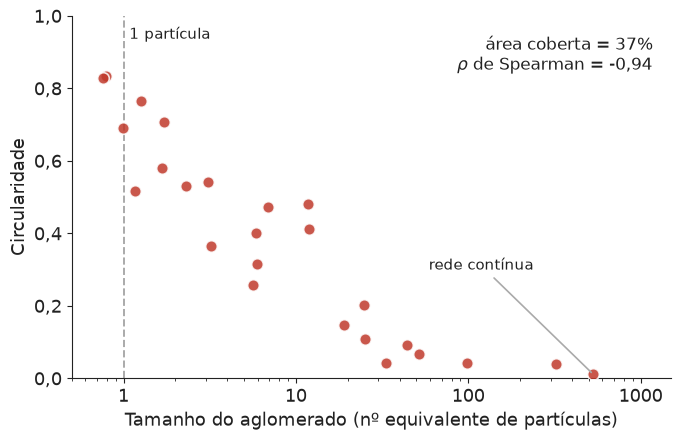

Salvo em: c:\Users\gabriela2610013\OneDrive - ILUM ESCOLA DE CIÊNCIA\Área de Trabalho\Relatório IP-1\aglomerados_mev_escuro.png


In [16]:
"""Aglomerados de nanopartículas de sílica no MEV (Analyze Particles do Fiji).

Lê a tabela Results do Analyze Particles (csv) e gera:
- circularidade x tamanho do aglomerado (em número equivalente de partículas);
- resumo no terminal (fração de área coberta, maior aglomerado etc.).
Versões _claro (relatório) e _escuro (fundo transparente, para slides).
Uso: python3 grafico_aglomerados.py
"""
import csv
import os
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, FixedLocator
from scipy import stats

ARQUIVO = "dados_FTIR_RAMAN_MEV/aglomeradosnps.csv"
LARGURA_NM, ALTURA_NM = 1185.0, 785.37   # tamanho da imagem recortada (topo da janela do Fiji)
D_PARTICULA = 19.0                        # diâmetro médio medido no MEV (nm)

linhas = list(csv.DictReader(open(ARQUIVO, encoding="utf-8")))
area = np.array([float(l["Area"]) for l in linhas])
circ = np.array([float(l["Circ."]) for l in linhas])
area_part = np.pi * D_PARTICULA**2 / 4
n_eq = area / area_part                   # número equivalente de partículas (projeção 2D)

cobertura = 100 * area.sum() / (LARGURA_NM * ALTURA_NM)
ordem = np.argsort(-area)
rho, p = stats.spearmanr(area, circ)
print(f"{len(area)} objetos | área coberta = {cobertura:.0f}% da imagem")
print(f"maior aglomerado: {area[ordem[0]]:.0f} nm² (~{n_eq[ordem[0]]:.0f} partículas), "
      f"{100 * area[ordem[0]] / area.sum():.0f}% da área ocupada")
print(f"3 maiores: {100 * area[ordem[:3]].sum() / area.sum():.0f}% da área ocupada")
print(f"Spearman (área × circularidade): rho = {rho:.2f}, p = {p:.1g}")

def br(v, n=2):
    return f"{v:.{n}f}".replace(".", ",")

for FUNDO_ESCURO in (False, True):
    if FUNDO_ESCURO:
        FUNDO, TXT, GRID, COR, SUF = "#231D1F", "#F4ECE8", "#8C8285", "#de295f", "_escuro"
    else:
        FUNDO, TXT, GRID, COR, SUF = "white", "#222222", "#AAAAAA", "#C0392B", "_claro"
    plt.rcParams.update({
        "font.size": 13, "text.color": TXT, "axes.labelcolor": TXT,
        "xtick.color": TXT, "ytick.color": TXT, "axes.edgecolor": TXT,
        "figure.facecolor": FUNDO, "axes.facecolor": FUNDO,
    })
    fig, ax = plt.subplots(figsize=(7, 4.6))
    ax.scatter(n_eq, circ, s=70, color=COR, alpha=0.85, edgecolor=FUNDO, linewidth=1.2, zorder=3)
    ax.axvline(1, color=GRID, ls="--", lw=1.4, zorder=1)
    ax.text(1.08, 0.97, "1 partícula", color=TXT, fontsize=11, va="top")
    i = ordem[0]
    ax.annotate("rede contínua", (n_eq[i], circ[i]), xytext=(n_eq[i] / 9, 0.30),
                fontsize=11, color=TXT, arrowprops=dict(arrowstyle="-", color=GRID, lw=1.2))
    ax.text(0.97, 0.95, f"área coberta = {cobertura:.0f}%\n"
            f"$\\rho$ de Spearman = {br(rho)}".replace(".", ","),
            transform=ax.transAxes, ha="right", va="top", fontsize=12, color=TXT)
    ax.set_xscale("log")
    ax.set_xlim(0.5, 1500)
    ax.set_ylim(0, 1.0)
    ax.xaxis.set_major_locator(FixedLocator([1, 10, 100, 1000]))
    ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.0f}"))
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: br(v, 1)))
    ax.set_xlabel("Tamanho do aglomerado (nº equivalente de partículas)")
    ax.set_ylabel("Circularidade")
    ax.spines[["top", "right"]].set_visible(False)
    plt.tight_layout()
    nome = f"aglomerados_mev{SUF}.png"
    fig.savefig(nome, dpi=300, transparent=FUNDO_ESCURO, bbox_inches="tight")
    print("Salvo em:", os.path.abspath(nome))
    if not FUNDO_ESCURO:
        plt.show()
    plt.close(fig)

(a) n = 800, 19.0 ± 6.2 nm | (b) 25 aglomerados, cobertura 37%, rho = -0.94
Salvo em: c:\Users\gabriela2610013\OneDrive - ILUM ESCOLA DE CIÊNCIA\Área de Trabalho\Relatório IP-1\painel_mev_claro.png


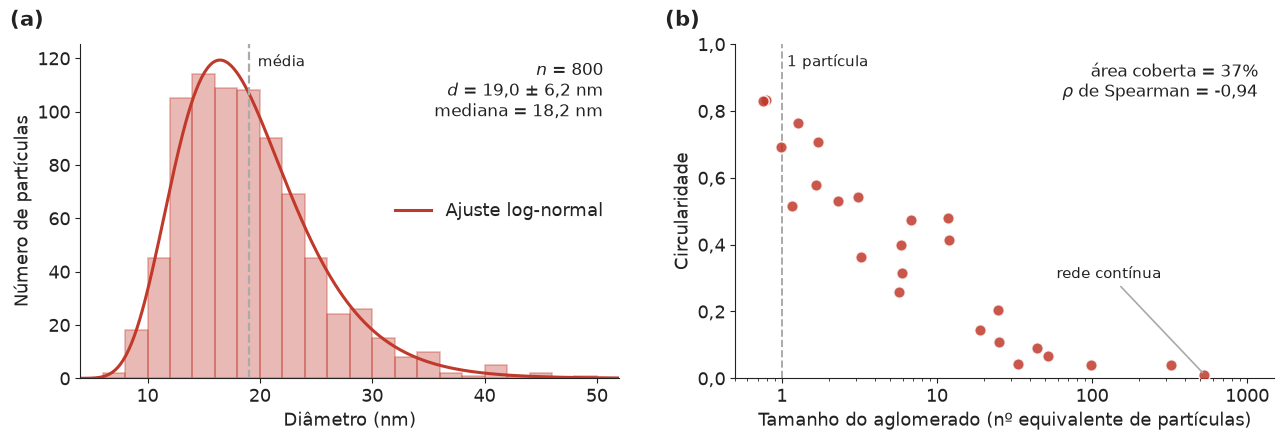

Salvo em: c:\Users\gabriela2610013\OneDrive - ILUM ESCOLA DE CIÊNCIA\Área de Trabalho\Relatório IP-1\painel_mev_escuro.png


In [17]:
"""Painel do MEV: (a) distribuição de diâmetro das partículas; (b) aglomerados.

Precisa, na mesma pasta:
- medidas_mev.txt  -> tabela Results do Fiji com as linhas de diâmetro (coluna Length)
- aglomerados.csv  -> tabela Results do Analyze Particles
Gera painel_mev_claro.png (relatório) e painel_mev_escuro.png (fundo transparente).
Uso: python3 painel_mev.py
"""
import csv
import os
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, FixedLocator
from scipy import stats

ARQ_DIAMETROS = "dados_FTIR_RAMAN_MEV/aglomerados.csv"
ARQ_AGLOMERADOS = "dados_FTIR_RAMAN_MEV/aglomeradosnps.csv"
FATOR = 500 / 3375          # correção da escala usada nas medidas de diâmetro
ULTIMA_LINHA = 801          # linhas depois desta (medidas de forma) são ignoradas
LARGURA_NM, ALTURA_NM = 1185.0, 785.37   # imagem recortada usada no Analyze Particles


def ler_tabela(arquivo):
    texto = open(arquivo, encoding="utf-8-sig").read().splitlines()
    sep = "\t" if "\t" in texto[0] else ","
    tabela = [l for l in csv.reader(texto, delimiter=sep) if any(c.strip() for c in l)]
    cab = None
    if not tabela[0][0].strip().isdigit():
        cab, tabela = [c.strip() for c in tabela[0]], tabela[1:]
    return cab, tabela


# ---------- (a) diâmetros ----------
cab, tab = ler_tabela(ARQ_DIAMETROS)
col = cab.index("Length") if cab and "Length" in cab else -1
anterior, d = None, []
for l in tab:
    if int(l[0]) > ULTIMA_LINHA:
        continue
    if tuple(l[2:]) == anterior:        # Ctrl+M repetido
        continue
    anterior = tuple(l[2:])
    d.append(float(l[col]) * FATOR)
d = np.array(d)
media, dp, mediana = d.mean(), d.std(ddof=1), np.median(d)
forma, _, escala = stats.lognorm.fit(d, floc=0)

# ---------- (b) aglomerados ----------
cab, tab = ler_tabela(ARQ_AGLOMERADOS)
area = np.array([float(l[cab.index("Area")]) for l in tab])
circ = np.array([float(l[cab.index("Circ.")]) for l in tab])
n_eq = area / (np.pi * media**2 / 4)
cobertura = 100 * area.sum() / (LARGURA_NM * ALTURA_NM)
rho, _ = stats.spearmanr(area, circ)
print(f"(a) n = {len(d)}, {media:.1f} ± {dp:.1f} nm | (b) {len(area)} aglomerados, "
      f"cobertura {cobertura:.0f}%, rho = {rho:.2f}")


def br(v, n=1):
    return f"{v:.{n}f}".replace(".", ",")


for FUNDO_ESCURO in (False, True):
    if FUNDO_ESCURO:
        FUNDO, TXT, GRID, COR, SUF = "#231D1F", "#F4ECE8", "#8C8285", "#de295f", "_escuro"
    else:
        FUNDO, TXT, GRID, COR, SUF = "white", "#222222", "#AAAAAA", "#C0392B", "_claro"
    plt.rcParams.update({
        "font.size": 13, "text.color": TXT, "axes.labelcolor": TXT,
        "xtick.color": TXT, "ytick.color": TXT, "axes.edgecolor": TXT,
        "figure.facecolor": FUNDO, "axes.facecolor": FUNDO, "legend.labelcolor": TXT,
    })
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.6))

    # (a) histograma
    a1.hist(d, bins=np.arange(6, 52, 2), color=COR, alpha=0.35, edgecolor=COR, linewidth=1.2)
    xs = np.linspace(4, 52, 400)
    a1.plot(xs, stats.lognorm.pdf(xs, forma, 0, escala) * len(d) * 2, color=COR, lw=2.2,
            label="Ajuste log-normal")
    a1.axvline(media, color=GRID, ls="--", lw=1.6)
    a1.text(media + 0.8, a1.get_ylim()[1] * 0.97, "média", color=TXT, fontsize=11, va="top")
    a1.text(0.97, 0.95, f"$n$ = {len(d)}\n$d$ = {br(media)} ± {br(dp)} nm\n"
            f"mediana = {br(mediana)} nm", transform=a1.transAxes, ha="right", va="top",
            fontsize=12, color=TXT)
    a1.legend(frameon=False, loc="center right", labelcolor=TXT)
    a1.set_xlim(4, 52)
    a1.set_xlabel("Diâmetro (nm)")
    a1.set_ylabel("Número de partículas")

    # (b) aglomerados
    a2.scatter(n_eq, circ, s=70, color=COR, alpha=0.85, edgecolor=FUNDO, linewidth=1.2, zorder=3)
    a2.axvline(1, color=GRID, ls="--", lw=1.4, zorder=1)
    a2.text(1.08, 0.97, "1 partícula", color=TXT, fontsize=11, va="top")
    i = np.argmax(area)
    a2.annotate("rede contínua", (n_eq[i], circ[i]), xytext=(n_eq[i] / 9, 0.30), fontsize=11,
                color=TXT, arrowprops=dict(arrowstyle="-", color=GRID, lw=1.2))
    a2.text(0.97, 0.95, f"área coberta = {cobertura:.0f}%\n$\\rho$ de Spearman = {br(rho, 2)}",
            transform=a2.transAxes, ha="right", va="top", fontsize=12, color=TXT)
    a2.set_xscale("log")
    a2.set_xlim(0.5, 1500)
    a2.set_ylim(0, 1.0)
    a2.xaxis.set_major_locator(FixedLocator([1, 10, 100, 1000]))
    a2.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.0f}"))
    a2.yaxis.set_major_formatter(FuncFormatter(lambda v, _: br(v, 1)))
    a2.set_xlabel("Tamanho do aglomerado (nº equivalente de partículas)")
    a2.set_ylabel("Circularidade")

    for ax, letra in ((a1, "(a)"), (a2, "(b)")):
        ax.spines[["top", "right"]].set_visible(False)
        ax.text(-0.13, 1.04, letra, transform=ax.transAxes, fontsize=15, fontweight="bold",
                color=TXT, va="bottom")

    plt.tight_layout(w_pad=3)
    nome = f"painel_mev{SUF}.png"
    fig.savefig(nome, dpi=300, transparent=FUNDO_ESCURO, bbox_inches="tight")
    print("Salvo em:", os.path.abspath(nome))
    if not FUNDO_ESCURO:
        plt.show()
    plt.close(fig)